In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [2]:
# data = pd.read_csv(r"C:\Users\Dell\Documents\ML Projects\car_data.csv")
data = pd.read_csv("/kaggle/input/datasets/muhammadismailo/car-data-set/car_data.csv")

In [3]:
data.head()

,User ID,Gender,Age,AnnualSalary,Purchased
0,385,Male,35,20000,0
1,681,Male,40,43500,0
2,353,Male,49,74000,0
3,895,Male,40,107500,1
4,661,Male,25,79000,0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   User ID       1000 non-null   int64 
 1   Gender        1000 non-null   object
 2   Age           1000 non-null   int64 
 3   AnnualSalary  1000 non-null   int64 
 4   Purchased     1000 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 39.2+ KB


In [5]:
data.describe()

,User ID,Age,AnnualSalary,Purchased
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,40.106000,72689.000000,0.402000
std,288.819436,10.707073,34488.341867,0.490547
min,1.000000,18.000000,15000.000000,0.000000
25%,250.750000,32.000000,46375.000000,0.000000
50%,500.500000,40.000000,72000.000000,0.000000
75%,750.250000,48.000000,90000.000000,1.000000
max,1000.000000,63.000000,152500.000000,1.000000


In [6]:
data.isnull().sum()

User ID         0
Gender          0
Age             0
AnnualSalary    0
Purchased       0
dtype: int64

In [7]:
data['Purchased'].value_counts()

Purchased
0    598
1    402
Name: count, dtype: int64

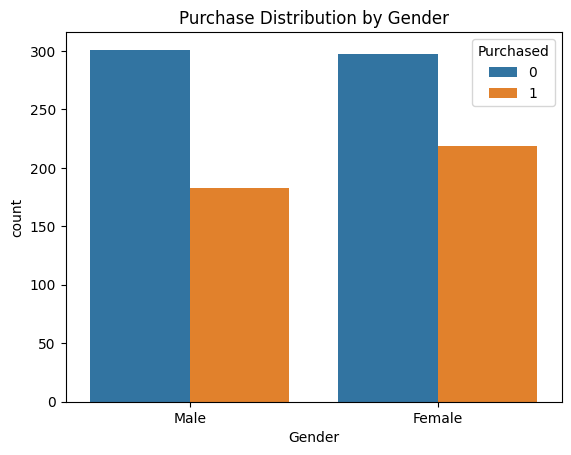

In [8]:
sns.countplot(data=data, x='Gender', hue='Purchased')
plt.title('Purchase Distribution by Gender')
plt.show()

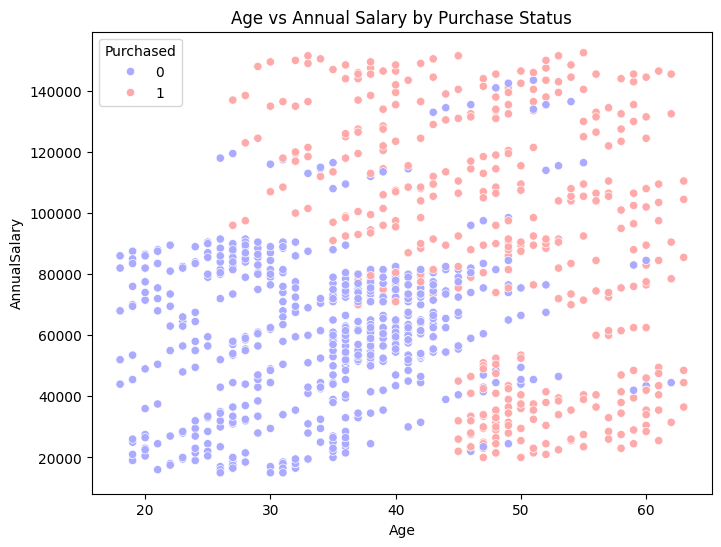

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x='Age', y='AnnualSalary', hue='Purchased', palette='bwr')
plt.title('Age vs Annual Salary by Purchase Status')
plt.show()

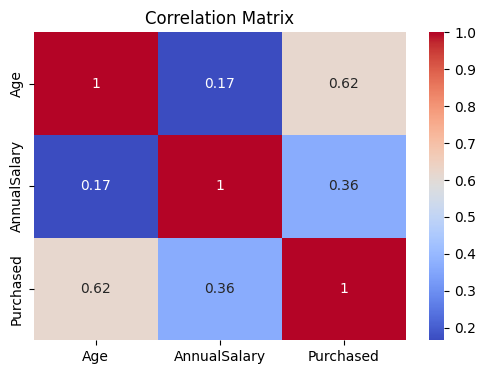

In [10]:
plt.figure(figsize=(6, 4))
sns.heatmap(data[['Age', 'AnnualSalary', 'Purchased']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [11]:
X=data.iloc[:,2:4]
y=data.iloc[:,4]

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,stratify=y, random_state=42)

In [13]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [14]:
from sklearn.linear_model import LogisticRegression
clf=LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

In [15]:
y_pred = clf.predict(X_test)

In [16]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.85

Confusion Matrix:
 [[107  13]
 [ 17  63]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.89      0.88       120
           1       0.83      0.79      0.81        80

    accuracy                           0.85       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.85      0.85       200



In [17]:
y_prob = clf.predict_proba(X_test)[:, 1]

In [18]:
y_pred_proba= clf.predict_proba(X_test)
y_pred_proba[0:5]

array([[0.81418711, 0.18581289],
       [0.17696892, 0.82303108],
       [0.28914432, 0.71085568],
       [0.08321264, 0.91678736],
       [0.99848514, 0.00151486]])

In [19]:
pred1=np.argmax(y_pred_proba,axis=1)
pred1[0:5]

array([0, 1, 1, 1, 0])

In [20]:
loss = (- y_test * np.log(y_prob) - (1 - y_test) * np.log(1 - y_prob)).mean()
print(f"\nBinary Cross Entropy Loss: {loss}")


Binary Cross Entropy Loss: 0.36267249365228954


In [21]:
from sklearn.metrics import log_loss
 
loss_sckit=log_loss(y_test,y_pred_proba)
loss_sckit

0.36267249365228954

In [22]:
from keras.utils import to_categorical
y_test_cat=to_categorical(y_test)

I0000 00:00:1794929063.600651      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794929082.265349      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [23]:
loss = (-y_test * np.log(y_pred_proba[:, 1]) - (1 - y_test) * np.log(1 - y_pred_proba[:, 1])).mean()
loss

np.float64(0.36267249365228954)

In [24]:
loss = -np.sum(y_test_cat * np.log(y_pred_proba), axis=1).mean()
loss


np.float64(0.36267249365228954)

In [25]:
w=clf.coef_
w=w.ravel()
w

array([2.20169921, 1.06682962])

In [26]:
b=clf.intercept_
b

array([-0.72626216])

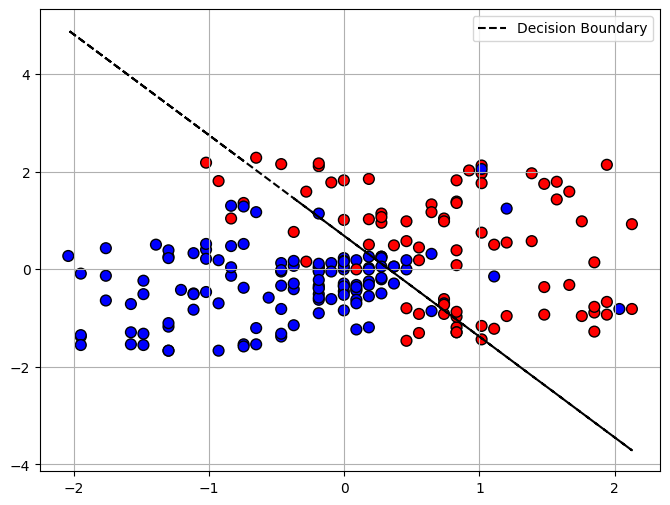

In [27]:
yy=-(w[0] * X_test[:,0]+b)/w[1]

plt.figure(figsize=(8,6))
plt.scatter(X_test[:,0],X_test[:,1],c=y_test,cmap='bwr',edgecolor='k',s=60)
# plt.scatter(X_test[:,0][y_test==0], X_test[:,1][y_test==0], label="0",  c='green')
# plt.scatter(X_test[:,0][y_test==1], X_test[:,1][y_test==1], label="1",  c='red')
plt.plot(X_test[:,0],yy,'k--',label="Decision Boundary")
plt.grid()
plt.legend()
plt.show()

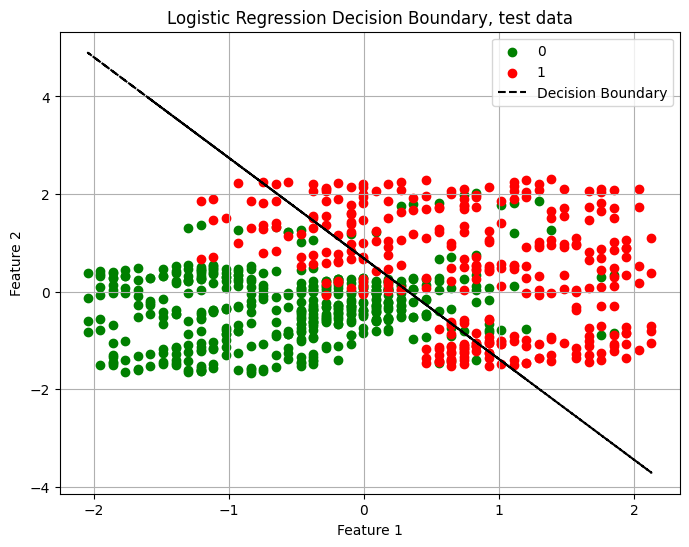

In [28]:
yy = -(w[0] * X_train[:, 0] + b) / w[1]   # wx+b=0  , w1x1+w2x2+b=0, x2= -(w1x1+b)/w2
 
# Plotting
plt.figure(figsize=(8, 6))
# plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr', edgecolor='k', s=60)
plt.scatter(X_train[:,0][y_train==0], X_train[:,1][y_train==0], label="0",  c='green')
plt.scatter(X_train[:,0][y_train==1], X_train[:,1][y_train==1], label="1",  c='red')
plt.plot(X_train[:, 0], yy, 'k--', label='Decision Boundary')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Logistic Regression Decision Boundary, test data' )
plt.legend()
plt.grid(True)